# Bicopter
Run All with `src/.venv`. Edit `settings`, then rerun the last cell.
Firmware and simulation share the C math in `fw/drone/main/flight_math.c` through `sw/sim/flight.py`.
The controller receives only accel/gyro. Position and altitude are uncontrolled.


In [2]:
from IPython.display import Image, display
from sw.sim.slop import simulation as sim

In [3]:
settings = {
    **sim.DEFAULT_TUNING,
    "enabled": True,
    "roll": 0.0,
    "pitch": 0.0,
    "yaw_rate": 0.0,
    "base_throttle": 0.0,
}


def commands(t, accel, gyro):
    attitude = estimator.update(accel, gyro, 0.01, powered=t >= 3)

    # Simulation-only takeoff sequence. Hardware collective comes from the dashboard.
    lift = 0 if t < 3 else 1.10 if t < 4 else 0.90 if t < 5 else 1.0
    settings["base_throttle"] = sim.throttle(sim.mass * 9.81 * lift / 2)

    controller.configure(settings)
    return controller.update(attitude, gyro, 0.01)

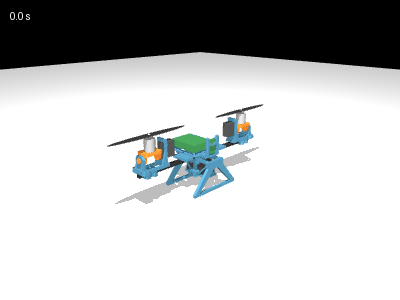

In [4]:
estimator = sim.Attitude()
controller = sim.Controller()
gif, readings = sim.run(commands, seconds=60)
display(Image(filename=str(gif)))